# US Mortgage Origination Data Analysis

## Project Overview

This project analyzes U.S. mortgage origination data to understand borrower characteristics, loan characteristics, geographic distribution, and relationships between key mortgage variables.

The analysis covers data preparation, exploratory data analysis, statistical relationships, visualization, and business insights.

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 1. Data Loading and Initial Inspection

In [1]:
import os

In [2]:
import os
print(os.getcwd())

C:\Users\ACER


In [9]:
os.listdir(r'C:\Users\ACER\Desktop\Project data')

['file_layout_july_2026.xlsx',
 'sample_2024.zip',
 'sample_orig_2024.txt',
 'sample_svcg_2024.txt',
 'US mortage.pbix',
 'US_Mortgage_Cleaned.csv']

In [10]:
df = pd.read_csv("sample_orig_2024.txt",sep="|",header=None)

FileNotFoundError: [Errno 2] No such file or directory: 'sample_orig_2024.txt'

In [5]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,812,202403,N,205402,16984.0,0,1,P,38,23,...,2,Other sellers,Other servicers,NaN,NaN,9,NaN,2,N,7
1,797,202403,N,205402,NaN,0,1,P,80,30,...,1,Other sellers,Other servicers,NaN,NaN,H,NaN,1,N,7
2,775,202403,N,203902,30700.0,25,1,P,95,42,...,2,Other sellers,Other servicers,NaN,NaN,9,NaN,2,N,N
3,768,202403,N,205402,45820.0,0,1,P,80,37,...,2,Other sellers,NATIONSTAR MORTGAGE LLC DBA MR. COOPER,NaN,NaN,9,NaN,2,N,7
4,776,202403,N,205402,43100.0,0,1,P,64,32,...,2,Other sellers,NATIONSTAR MORTGAGE LLC DBA MR. COOPER,NaN,NaN,9,NaN,1,N,7


In [6]:
df.shape

(50000, 32)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       50000 non-null  int64  
 1   1       50000 non-null  int64  
 2   2       50000 non-null  object 
 3   3       50000 non-null  int64  
 4   4       44672 non-null  float64
 5   5       50000 non-null  int64  
 6   6       50000 non-null  int64  
 7   7       50000 non-null  object 
 8   8       50000 non-null  int64  
 9   9       50000 non-null  int64  
 10  10      50000 non-null  int64  
 11  11      50000 non-null  int64  
 12  12      50000 non-null  float64
 13  13      50000 non-null  object 
 14  14      50000 non-null  object 
 15  15      50000 non-null  object 
 16  16      50000 non-null  object 
 17  17      50000 non-null  object 
 18  18      50000 non-null  int64  
 19  19      50000 non-null  object 
 20  20      50000 non-null  object 
 21  21      50000 non-null  int64  
 22

## 2. Load Data Dictionary and Assign Column Names

In [8]:
layout = pd.read_excel("file_layout_july_2026.xlsx",sheet_name="Origination Data File",header=1)
layout.head()

,Field Position,Attribute Name,Data Type & Format,Max Length
0,1,Classic FICO®,Numeric,4
1,2,First Payment Date,Date,6
2,3,First Time Homebuyer Indicator,Alpha,1
3,4,Maturity Date,Date,6
4,5,Metropolitan Statistical Area (MSA) Or Metropo...,Numeric,5


In [9]:
columns=layout["Attribute Name"].tolist()


## 3. Assign Column Names and Validate Data Structure

In [10]:
# Insert Servicer Name to align the dataset with the official file layout.
columns.insert(24, "Servicer Name")

In [11]:
df.columns = columns

In [12]:
df.head()

,Classic FICO®,First Payment Date,First Time Homebuyer Indicator,Maturity Date,Metropolitan Statistical Area (MSA) Or Metropolitan Division,Mortgage Insurance Percentage (MI %),Number of Units,Occupancy Status,Original Combined Loan-to-Value (CLTV),Original Debt-to-Income (DTI) Ratio,...,Number of Borrowers,Seller Name,Servicer Name,Super Conforming Flag,Pre-HARP Loan Sequence Number,Special Eligibility Program,HARP Indicator,Property Valuation Method,Interest Only (I/O) Indicator,VantageScore® 4.0
0,812,202403,N,205402,16984.0,0,1,P,38,23,...,2,Other sellers,Other servicers,NaN,NaN,9,NaN,2,N,7
1,797,202403,N,205402,NaN,0,1,P,80,30,...,1,Other sellers,Other servicers,NaN,NaN,H,NaN,1,N,7
2,775,202403,N,203902,30700.0,25,1,P,95,42,...,2,Other sellers,Other servicers,NaN,NaN,9,NaN,2,N,N
3,768,202403,N,205402,45820.0,0,1,P,80,37,...,2,Other sellers,NATIONSTAR MORTGAGE LLC DBA MR. COOPER,NaN,NaN,9,NaN,2,N,7
4,776,202403,N,205402,43100.0,0,1,P,64,32,...,2,Other sellers,NATIONSTAR MORTGAGE LLC DBA MR. COOPER,NaN,NaN,9,NaN,1,N,7


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 32 columns):
 #   Column                                                        Non-Null Count  Dtype  
---  ------                                                        --------------  -----  
 0   Classic FICO®                                                 50000 non-null  int64  
 1   First Payment Date                                            50000 non-null  int64  
 2   First Time Homebuyer Indicator                                50000 non-null  object 
 3   Maturity Date                                                 50000 non-null  int64  
 4   Metropolitan Statistical Area (MSA) Or Metropolitan Division  44672 non-null  float64
 5   Mortgage Insurance Percentage (MI %)                          50000 non-null  int64  
 6   Number of Units                                               50000 non-null  int64  
 7   Occupancy Status                                              50000

## 4. Data Quality and Cleaning

In [14]:
df.isnull().sum()

Classic FICO®                                                       0
First Payment Date                                                  0
First Time Homebuyer Indicator                                      0
Maturity Date                                                       0
Metropolitan Statistical Area (MSA) Or Metropolitan Division     5328
Mortgage Insurance Percentage (MI %)                                0
Number of Units                                                     0
Occupancy Status                                                    0
Original Combined Loan-to-Value (CLTV)                              0
Original Debt-to-Income (DTI) Ratio                                 0
Original UPB                                                        0
Original Loan-to-Value (LTV)                                        0
Original Interest Rate                                              0
Channel                                                             0
Prepayment Penalty I

In [15]:
df.describe()

,Classic FICO®,First Payment Date,Maturity Date,Metropolitan Statistical Area (MSA) Or Metropolitan Division,Mortgage Insurance Percentage (MI %),Number of Units,Original Combined Loan-to-Value (CLTV),Original Debt-to-Income (DTI) Ratio,Original UPB,Original Loan-to-Value (LTV),Original Interest Rate,Postal Code,Original Loan Term,Number of Borrowers,Pre-HARP Loan Sequence Number,HARP Indicator,Property Valuation Method
count,50000.000000,50000.000000,50000.000000,44672.000000,50000.000000,50000.000000,50000.000000,50000.00000,5.000000e+04,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,0.0,0.0,50000.000000
mean,755.541700,202421.740380,205316.575580,29297.921159,9.488360,1.025300,75.017200,37.86478,3.404037e+05,74.788320,6.690835,51365.704000,348.280960,1.48184,NaN,NaN,1.875900
std,171.346507,33.664246,363.923565,11109.764364,13.099422,0.202733,19.655375,10.26040,1.905587e+05,19.507418,0.595851,27995.320812,43.620627,0.54070,NaN,NaN,0.446703
min,558.000000,202402.000000,203201.000000,10180.000000,0.000000,1.000000,4.000000,1.00000,1.300000e+04,4.000000,2.500000,600.000000,85.000000,1.00000,NaN,NaN,1.000000
25%,724.000000,202405.000000,205404.000000,19124.000000,0.000000,1.000000,65.000000,32.00000,1.950000e+05,65.000000,6.375000,29700.000000,360.000000,1.00000,NaN,NaN,2.000000
50%,763.000000,202408.000000,205407.000000,29620.000000,0.000000,1.000000,80.000000,40.00000,3.040000e+05,80.000000,6.625000,48000.000000,360.000000,1.00000,NaN,NaN,2.000000
75%,789.000000,202412.000000,205410.000000,38900.000000,25.000000,1.000000,90.000000,45.00000,4.500000e+05,90.000000,7.000000,77300.000000,360.000000,2.00000,NaN,NaN,2.000000
max,9999.000000,202509.000000,205508.000000,49740.000000,35.000000,4.000000,136.000000,999.00000,1.620000e+06,136.000000,9.125000,99900.000000,360.000000,5.00000,NaN,NaN,4.000000


In [16]:
(df["Classic FICO®"] == 9999).sum()

np.int64(16)

In [17]:
# Replace the dataset's FICO missing-value code (9999) with NaN.
df["Classic FICO®"] = df["Classic FICO®"].replace(9999, np.nan)

In [18]:
df["Classic FICO®"].isnull().sum()

np.int64(16)

In [19]:
df["Classic FICO®"].describe()

count    49984.000000
mean       752.582847
std         44.829484
min        558.000000
25%        724.000000
50%        763.000000
75%        789.000000
max        832.000000
Name: Classic FICO®, dtype: float64

### Key Loan Characteristics

In [20]:
df["Original UPB"].describe()

count    5.000000e+04
mean     3.404037e+05
std      1.905587e+05
min      1.300000e+04
25%      1.950000e+05
50%      3.040000e+05
75%      4.500000e+05
max      1.620000e+06
Name: Original UPB, dtype: float64

In [21]:
df["Original UPB"].median()

304000.0

In [22]:
df["Original Interest Rate"].describe()


count    50000.000000
mean         6.690835
std          0.595851
min          2.500000
25%          6.375000
50%          6.625000
75%          7.000000
max          9.125000
Name: Original Interest Rate, dtype: float64

In [23]:
df["Original Loan-to-Value (LTV)"].describe()

count    50000.000000
mean        74.788320
std         19.507418
min          4.000000
25%         65.000000
50%         80.000000
75%         90.000000
max        136.000000
Name: Original Loan-to-Value (LTV), dtype: float64

In [24]:
(df["Original Loan-to-Value (LTV)"] > 100).sum()

np.int64(1)

In [25]:
df["Original Debt-to-Income (DTI) Ratio"].describe()

count    50000.00000
mean        37.86478
std         10.26040
min          1.00000
25%         32.00000
50%         40.00000
75%         45.00000
max        999.00000
Name: Original Debt-to-Income (DTI) Ratio, dtype: float64

In [26]:
(df["Original Debt-to-Income (DTI) Ratio"] == 999).sum()

np.int64(1)

In [27]:
# Replace the dataset's DTI missing-value code (999) with NaN.
df["Original Debt-to-Income (DTI) Ratio"] = (
    df["Original Debt-to-Income (DTI) Ratio"].replace(999, np.nan)
)

In [28]:
df["Original Debt-to-Income (DTI) Ratio"].isna().sum()

np.int64(1)

In [29]:
df["Original Debt-to-Income (DTI) Ratio"].describe()

count    49999.000000
mean        37.845557
std          9.316715
min          1.000000
25%         32.000000
50%         40.000000
75%         45.000000
max         65.000000
Name: Original Debt-to-Income (DTI) Ratio, dtype: float64

In [30]:
df["Original Combined Loan-to-Value (CLTV)"].isna().sum()

np.int64(0)

In [31]:
df["Original Combined Loan-to-Value (CLTV)"].describe()

count    50000.000000
mean        75.017200
std         19.655375
min          4.000000
25%         65.000000
50%         80.000000
75%         90.000000
max        136.000000
Name: Original Combined Loan-to-Value (CLTV), dtype: float64

In [32]:
(df["Original Combined Loan-to-Value (CLTV)"] > 100).sum()

np.int64(600)

## 5. Exploratory Data Analysis
### Loan and Borrower Characteristics

In [33]:
df["Loan Purpose"].value_counts()

Loan Purpose
P    39627
C     6269
N     4104
Name: count, dtype: int64

In [34]:
df["Occupancy Status"].value_counts()

Occupancy Status
P    45612
I     3437
S      951
Name: count, dtype: int64

In [35]:
df["Property Type"].value_counts()

Property Type
SF    29356
PU    15399
CO     4512
MH      644
CP       89
Name: count, dtype: int64

In [36]:
df["First Time Homebuyer Indicator"].value_counts(dropna=False)

First Time Homebuyer Indicator
N    31366
Y    18634
Name: count, dtype: int64

In [37]:
df["Channel"].value_counts()

Channel
R    24369
C    17554
B     8077
Name: count, dtype: int64

In [38]:
df["Property State"].value_counts().head(10)

Property State
TX    4619
FL    3935
CA    3647
IL    2431
OH    2225
PA    1895
MI    1893
NC    1759
GA    1727
NY    1668
Name: count, dtype: int64

In [39]:
df["Number of Borrowers"].value_counts()

Number of Borrowers
1    26855
2    22317
3      710
4      117
5        1
Name: count, dtype: int64

In [40]:
df["Number of Units"].value_counts()

Number of Units
1    49055
2      716
3      138
4       91
Name: count, dtype: int64

In [41]:
df["Mortgage Insurance Percentage (MI %)"].describe()

count    50000.000000
mean         9.488360
std         13.099422
min          0.000000
25%          0.000000
50%          0.000000
75%         25.000000
max         35.000000
Name: Mortgage Insurance Percentage (MI %), dtype: float64

In [42]:
(df["Mortgage Insurance Percentage (MI %)"]>0).sum()

np.int64(18166)

In [43]:
# Classify loans based on whether mortgage insurance is required.
df["MI Status"] = np.where(
    df["Mortgage Insurance Percentage (MI %)"] > 0,
    "MI Required",
    "No MI"
)

In [44]:
df["MI Status"].value_counts()

MI Status
No MI          31834
MI Required    18166
Name: count, dtype: int64

### Relationship Analysis

In [45]:
pd.crosstab(df["First Time Homebuyer Indicator"],df["MI Status"] ,margins=True) 

MI Status,MI Required,No MI,All
First Time Homebuyer Indicator,,,
N,7327,24039,31366
Y,10839,7795,18634
All,18166,31834,50000


In [46]:
df.groupby(df["MI Status"])["Original Loan-to-Value (LTV)"].mean()

MI Status
MI Required    92.811956
No MI          64.503173
Name: Original Loan-to-Value (LTV), dtype: float64

In [47]:
df.groupby(pd.cut(df["Original Loan-to-Value (LTV)"],bins=[0,80,90,100,150]),observed=False)["Classic FICO®"].mean()

Original Loan-to-Value (LTV)
(0, 80]       755.935261
(80, 90]      751.889331
(90, 100]     743.998320
(100, 150]    743.000000
Name: Classic FICO®, dtype: float64

In [48]:
df.groupby(pd.cut(df["Classic FICO®"],bins=[550,700,750,800,850]),observed=False)["Original Interest Rate"].mean()

Classic FICO®
(550, 700]    6.880094
(700, 750]    6.753107
(750, 800]    6.623793
(800, 850]    6.583694
Name: Original Interest Rate, dtype: float64

In [49]:
df.groupby("Loan Purpose")[["Classic FICO®","Original Loan-to-Value (LTV)"]].mean()

,Classic FICO®,Original Loan-to-Value (LTV)
Loan Purpose,,
C,731.242622,55.360823
N,754.964181,65.253899
P,755.713514,78.849194


In [50]:
df.groupby("Channel")["Classic FICO®"].mean()


Channel
B    754.206414
C    753.862116
R    751.122716
Name: Classic FICO®, dtype: float64

In [51]:
df.groupby("Channel")["Original Loan-to-Value (LTV)"].mean()

Channel
B    76.519005
C    76.742851
R    72.806763
Name: Original Loan-to-Value (LTV), dtype: float64

In [52]:
df.groupby("Occupancy Status")[["Classic FICO®","Original Loan-to-Value (LTV)"]].mean()

,Classic FICO®,Original Loan-to-Value (LTV)
Occupancy Status,,
I,760.067210,66.212976
P,751.766909,75.662326
S,764.654048,63.861199


In [53]:
df.groupby("Property Type")[["Classic FICO®","Original Loan-to-Value (LTV)"]].mean()

,Classic FICO®,Original Loan-to-Value (LTV)
Property Type,,
CO,758.187763,75.307402
CP,763.471910,71.033708
MH,736.007776,77.940994
PU,759.165649,73.720631
SF,748.598426,75.210826


### Geographic Analysis

In [54]:
#Top State Analysis

df["Property State"].value_counts().head(10)


Property State
TX    4619
FL    3935
CA    3647
IL    2431
OH    2225
PA    1895
MI    1893
NC    1759
GA    1727
NY    1668
Name: count, dtype: int64

In [55]:
#Average UPB by State
df.groupby("Property State")["Original UPB"].mean().sort_values(ascending=False).head(10)

Property State
HI    561957.264957
CA    521361.667124
DC    488423.529412
WA    470862.935929
MA    448186.592179
UT    434259.312321
CO    432048.234281
NJ    408277.346507
OR    399592.000000
VA    391167.275383
Name: Original UPB, dtype: float64

In [56]:
#Average FICO by State
df.groupby("Property State")["Classic FICO®"].mean().sort_values(ascending=False).head(10)

Property State
GU    780.666667
OR    763.302667
CO    763.250000
DE    760.803150
UT    760.196557
DC    760.152941
ND    759.411111
CA    759.055114
WA    758.137875
VA    758.002924
Name: Classic FICO®, dtype: float64

In [57]:
#States with Lowest Average Interest Rate
df.groupby("Property State")["Original Interest Rate"].mean().sort_values().head(10)

Property State
ND    6.461556
IA    6.509621
MT    6.549245
NV    6.573129
ID    6.593892
UT    6.601980
CO    6.602338
TX    6.628841
WY    6.632375
SD    6.637593
Name: Original Interest Rate, dtype: float64

## 6. Data Visualization

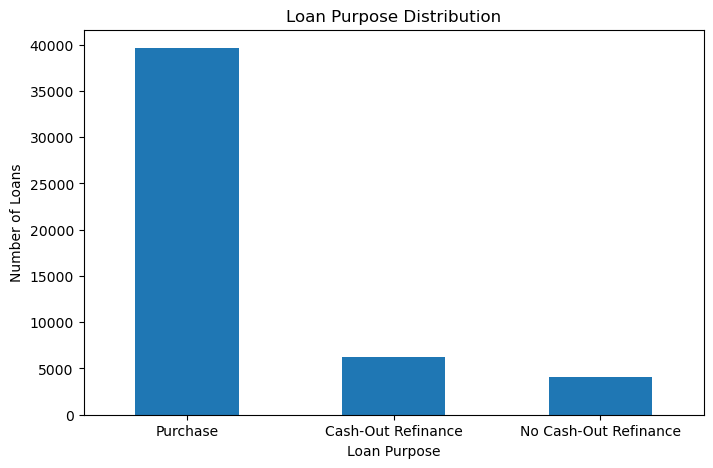

In [58]:
#Loan Purpose Distribution
plt.figure(figsize=(8,5))
loan_purpose_map={
    "P":"Purchase",
    "C":"Cash-Out Refinance",
    "N":"No Cash-Out Refinance"
}
df["Loan Purpose"].replace(loan_purpose_map).value_counts().plot(kind="bar")
plt.title("Loan Purpose Distribution")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)

plt.show()

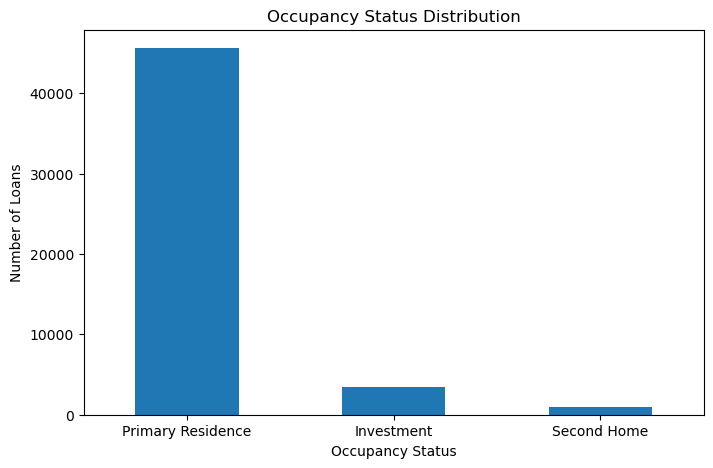

In [59]:
#Occupancy Status Distribution

occupancy_map={
    "P":"Primary Residence",
    "S":"Second Home",
    "I":"Investment"
 }
plt.figure(figsize=(8,5))

df["Occupancy Status"].replace(occupancy_map).value_counts().plot(kind="bar")

plt.title("Occupancy Status Distribution")
plt.xlabel("Occupancy Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)

plt.show()

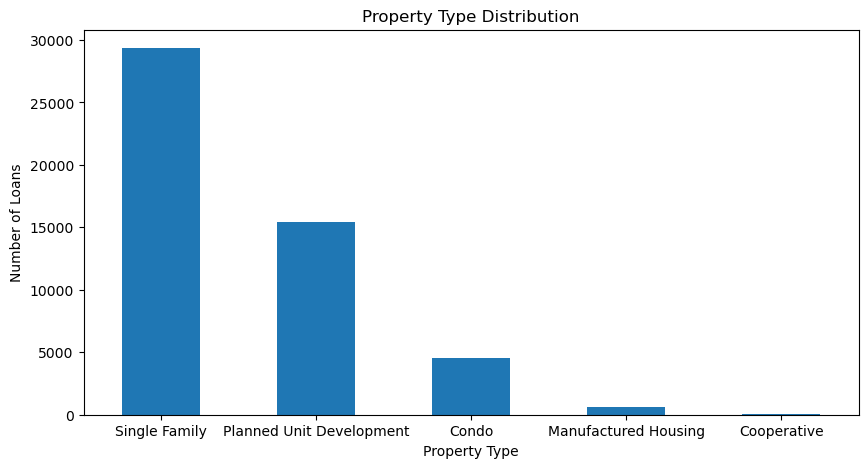

In [60]:
#Property Type Distribution

property_type_map={
    "SF": "Single Family",
    "PU":"Planned Unit Development",
    "CO":"Condo",
    "MH":"Manufactured Housing",
    "CP":"Cooperative"
 }

plt.figure(figsize=(10,5))
df["Property Type"].replace(property_type_map).value_counts().plot(kind="bar")

plt.title("Property Type Distribution")
plt.xlabel("Property Type")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.show()


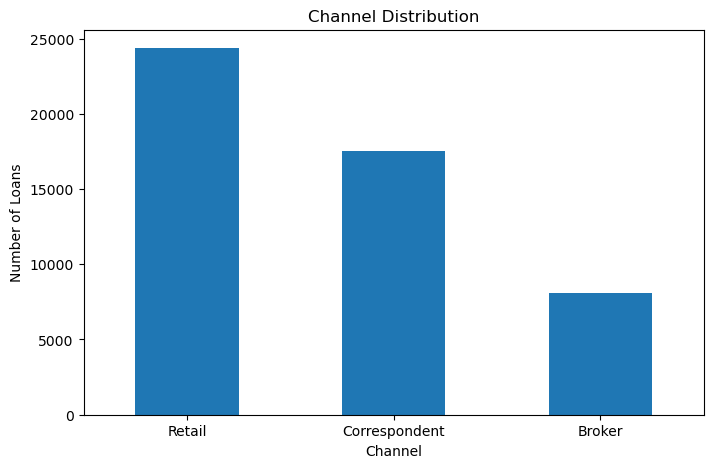

In [61]:
#Channel Distribution 

channel_map={
    "R":"Retail",
    "C":"Correspondent",
    "B":"Broker"
}

plt.figure(figsize=(8,5))
df["Channel"].replace(channel_map).value_counts().plot(kind="bar")
plt.title("Channel Distribution")
plt.xlabel("Channel")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.show()


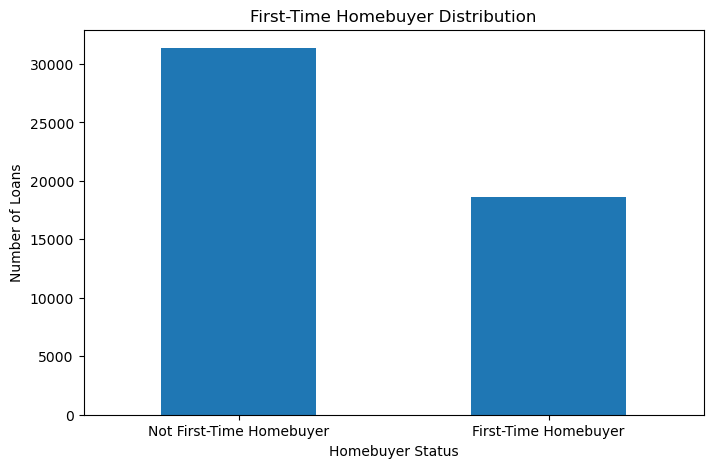

In [62]:
#First-Time Homebuyer Distribution

homebuyer_map={
    "Y":"First-Time Homebuyer",
    "N":"Not First-Time Homebuyer"
}

plt.figure(figsize=(8,5))

df["First Time Homebuyer Indicator"].replace(homebuyer_map).value_counts().plot(kind="bar")
plt.title("First-Time Homebuyer Distribution")
plt.xlabel("Homebuyer Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.show()

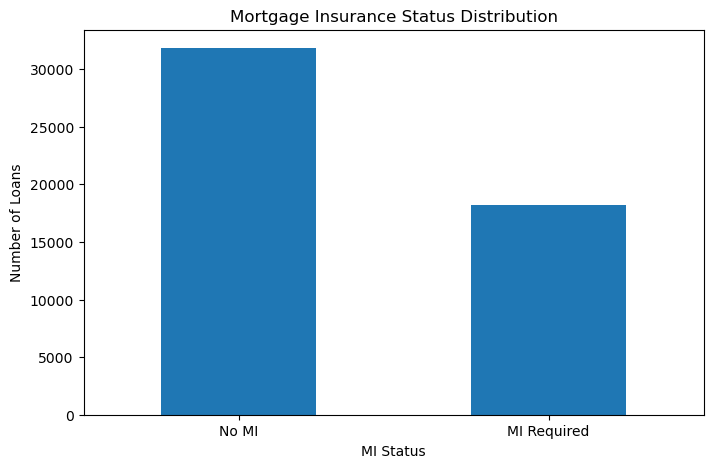

In [63]:
#MI Status Distribution

plt.figure(figsize=(8,5))

df["MI Status"].value_counts().plot(kind="bar")

plt.title("Mortgage Insurance Status Distribution")
plt.xlabel("MI Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=0)
plt.show()


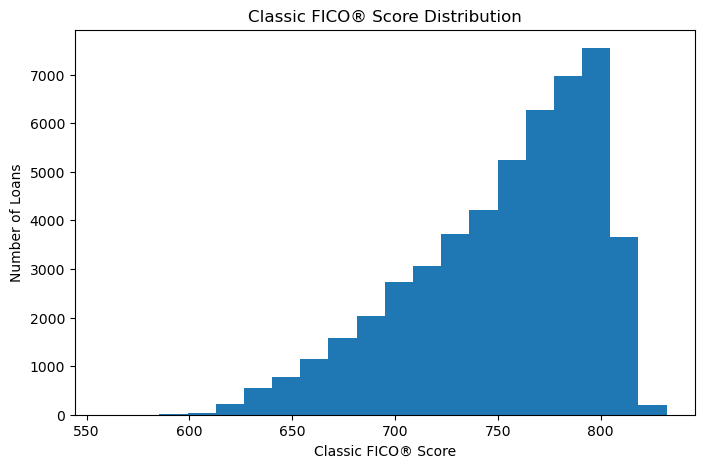

In [64]:
#Classic FICO Distribution

plt.figure(figsize=(8,5))

plt.hist(df["Classic FICO®"],bins=20)
plt.title("Classic FICO® Score Distribution")
plt.xlabel("Classic FICO® Score")
plt.ylabel("Number of Loans")
plt.show()

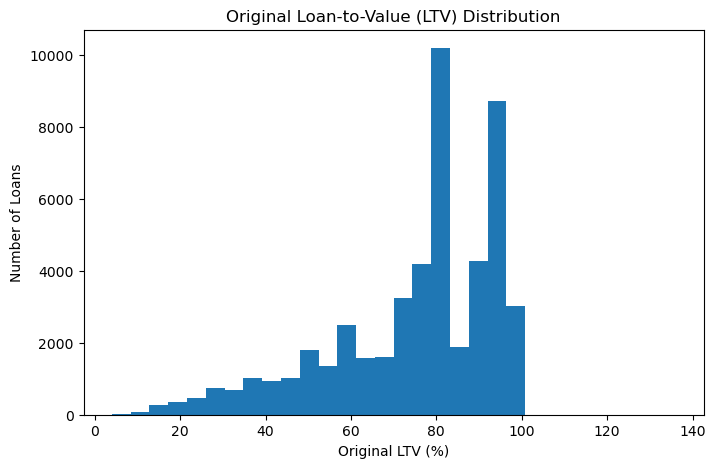

In [65]:
#Original LTV Distribution

plt.figure(figsize=(8,5))

plt.hist(df["Original Loan-to-Value (LTV)"],bins=30)

plt.title("Original Loan-to-Value (LTV) Distribution")
plt.xlabel("Original LTV (%)")
plt.ylabel("Number of Loans")
plt.show()
          

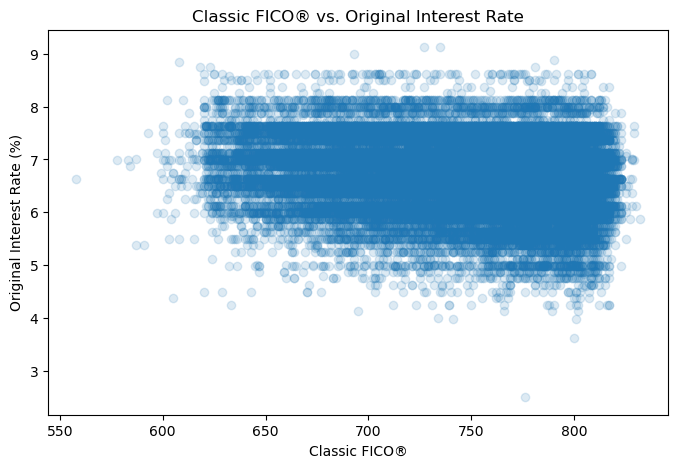

In [66]:
#FICO vs Original Interest Rate

plt.figure(figsize=(8,5))

plt.scatter(df["Classic FICO®"],df["Original Interest Rate"],alpha=0.15)
plt.title("Classic FICO® vs. Original Interest Rate")
plt.xlabel("Classic FICO®")
plt.ylabel("Original Interest Rate (%)")
plt.show()

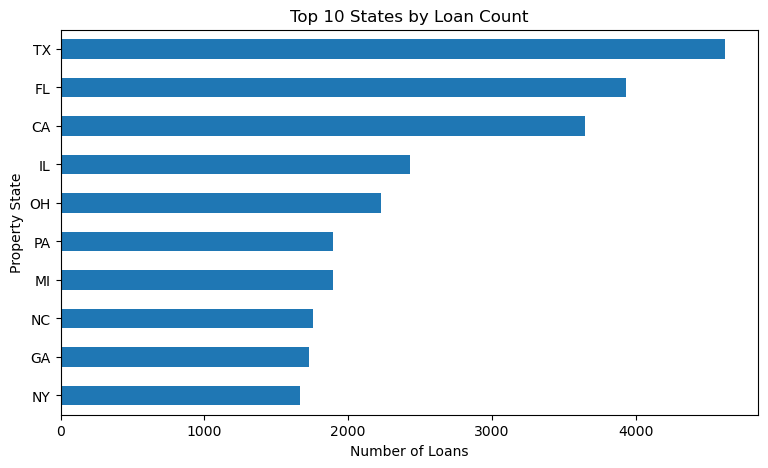

In [67]:
#Top 10 States by Loan Count

top_states=(df["Property State"].value_counts().head(10).sort_values())
plt.figure(figsize=(9,5))
top_states.plot(kind="barh")
plt.title("Top 10 States by Loan Count")
plt.xlabel("Number of Loans")
plt.ylabel("Property State")

plt.show()


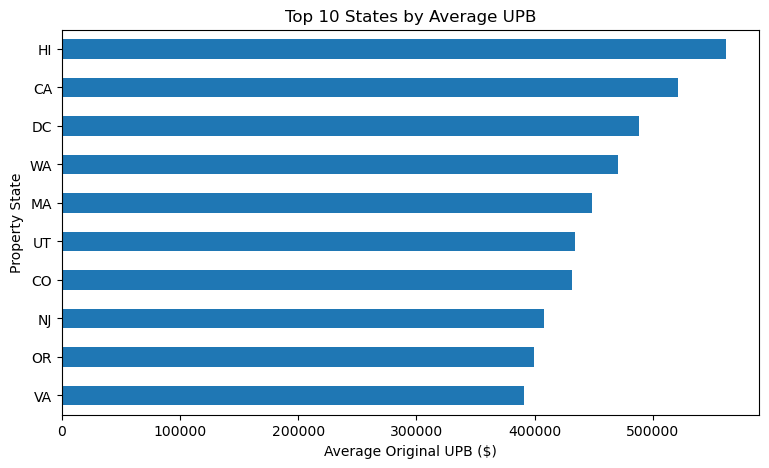

In [68]:
#Top 10 States by Average UPB

top_upb_states=(df.groupby("Property State")["Original UPB"].mean().sort_values(ascending=False).head(10).sort_values())
plt.figure(figsize=(9,5))

top_upb_states.plot(kind="barh")
plt.title("Top 10 States by Average UPB")
plt.xlabel("Average Original UPB ($)")
plt.ylabel("Property State")
plt.show()




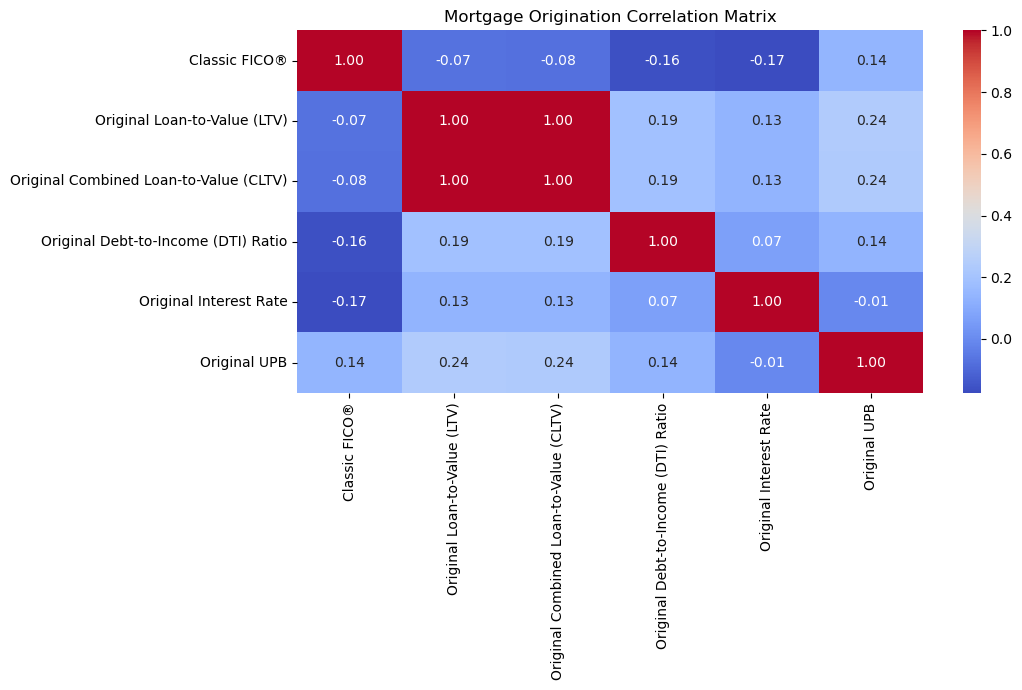

In [69]:
#Correlation Matrix

corr_matrix=df[["Classic FICO®","Original Loan-to-Value (LTV)","Original Combined Loan-to-Value (CLTV)",
                "Original Debt-to-Income (DTI) Ratio",
                "Original Interest Rate","Original UPB"]].corr()
plt.figure(figsize=(11,7))

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap="coolwarm")
plt.title("Mortgage Origination Correlation Matrix")
plt.tight_layout()
plt.show()


## 7. Business Insights

1. **Loan Purpose:** Purchase loans represent the largest share of the portfolio, while cash-out refinance and no-cash-out refinance loans account for smaller portions.

2. **Occupancy:** Primary residences make up the majority of loans, with investment properties and second homes representing smaller segments.

3. **Property Type:** Single-family properties account for the largest share of the portfolio, followed by planned unit developments and condos.

4. **Geographic Concentration:** Texas, Florida, and California are among the highest-volume states by loan count in the portfolio.

5. **Average Loan Balance:** Hawaii, California, and DC have the highest average Original UPB among the top 10 states by average UPB.

6. **Credit & Interest Rate:** Classic FICO® and Original Interest Rate show a weak negative correlation (-0.17), indicating only a limited linear relationship between credit score and interest rate in this dataset.

7. **LTV & CLTV:** Original LTV and Combined LTV show a correlation of 1.00 in the analyzed data, indicating a perfect linear correlation between the two variables.

8. **Mortgage Insurance:** 18,166 loans require mortgage insurance, while 31,834 loans do not, showing that the majority of loans in the dataset do not require MI.

In [74]:
df.to_csv("US_Mortgage_Cleaned.csv", index=False)